# Quickstart

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/quickstart.ipynb)

Run a first well: read a bundled well, plot it, interpret it and export the
result. Every output shown is computed from that well. Run it with Petrophys
installed ([Installation](https://petrophys.netlify.app/installation.html)), or open it in Google Colab with the button
above and run it in your browser, with nothing to install
([New to Python?](https://petrophys.netlify.app/new_to_python.html)).

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

In [2]:
import textwrap
import warnings
import pandas as pd

# Display settings for this page: whole table cells, warnings wrapped and without file paths.
pd.set_option("display.max_colwidth", None)
warnings.formatwarning = lambda message, category, *args, **kwargs: textwrap.fill(
    f"{category.__name__}: {message}", 88, subsequent_indent="    ") + "\n"

In [3]:
import petrophys as pp

well = pp.read(pp.sample("30_6-5"))   # or the path to your own LAS file
print(well)
print(f"{well.top:.1f} - {well.bottom:.1f} {well.depth_unit}")

Well(30/6-5, curves=20, samples=22176)
176.6 - 3556.1 m


## Plot the raw logs

`pp.plot` plots a well or an interpretation. Here it plots the logs as read,
before any interpretation, and `tracks=` picks four of the layout's tracks. The
window, 2800–3000 m, brackets the Brent Group (2841–2958 m).

    to v/v. Verify source units.
    to v/v. Verify source units.


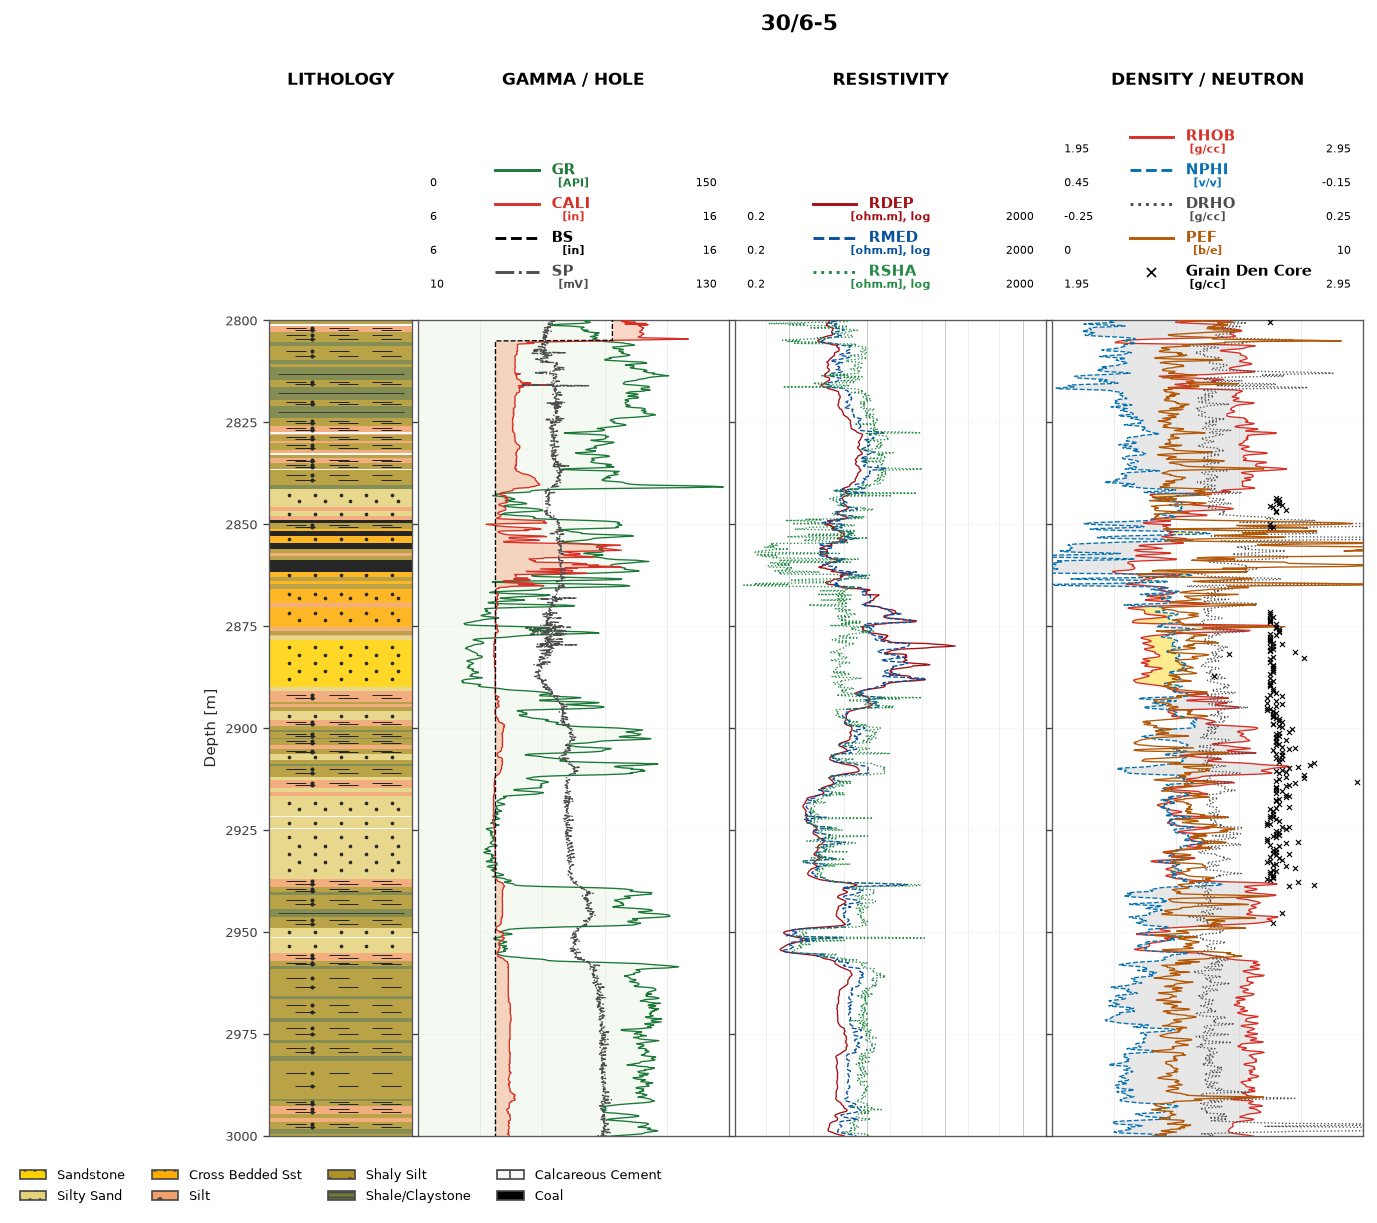

In [4]:
viewer = pp.plot(
    well,
    top=2800,
    bottom=3000,
    tracks=["LITHOLOGY", "GAMMA / HOLE", "RESISTIVITY", "DENSITY / NEUTRON"],
    figsize=(9.5, 10),
)
viewer.show()

## Interpret

`pp.interpret` works on a copy of the well. Settings are keywords: here the
formation-water resistivity `rw` and the temperature it was measured at.
[Interpretation settings](https://petrophys.netlify.app/api/settings.html) lists them all.

In [5]:
from textwrap import fill

result = pp.interpret(well, rw=0.07, rw_meas_temp_f=230)   # Rw 0.07 ohm.m at 230 degF

print("status:", result.status)
print("resolved:", result.config.matrix_type, "matrix,",
      result.config.lithology_domain, "domain")
for message in result.warnings:
    print(fill(f"warning: {message}", 88, subsequent_indent="    "))

    to v/v. Verify source units.
    to v/v. Verify source units.


status: interpreted
resolved: sandstone matrix, clastic domain
    matrix density is quartz-like (< 2.67 g/cm3) but the apparent matrix U calcite-like
    (> 10 b/cm3), the signature of barite-weighted mud; minerals solved without PEF
    Check the flag against the caliper and DRHO; bad_hole={'drho': ..., 'cali': ...}
    sets its thresholds and skip_steps=['bad_hole'] keeps the pay.


> **Note**
>
> These warnings are real: this LAS labels its core saturations `SWC` and `SOC`
> as fractions, but they hold percentages. Petrophys divides them by 100 for its
> core calibration and says so each time it reads them, so each message appears
> twice. They are Python warnings, not entries of `result.warnings`, which
> holds only the lithology message printed above. The rest of this page hides only these warnings; see
> [Core saturation units](https://petrophys.netlify.app/input_templates.html#core-saturation-units).

In [6]:
import warnings

# Hide only the SWC/SOC unit message explained above; other warnings stay visible.
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

| `result.status` | Meaning |
| --- | --- |
| `"interpreted"` | Steps ran and produced interpretation curves. |
| `"no_interpretation"` | Nothing failed, but the inputs supported no interpretation step. |
| `"failed"` | A step failed; `result.errors` says why and `result.raise_for_errors()` raises. |

To see the original exception while debugging, pass `raise_on_error=True`.

A step that cannot run is skipped with a reason, never filled with invented
defaults:

In [7]:
import pandas as pd

skipped = pd.DataFrame(result.specific_steps_skipped.items(),
                       columns=["Step", "Why it did not run"])
skipped.style.hide(axis="index")

Step,Why it did not run
spectral_gamma,Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
elemental_spectroscopy,Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
hc_correction,apply_hc_correction=False (hydrocarbon correction is opt-in)
porosity_refinement,Not run by the interpretation workflow; porosity is computed once in the porosity step


> **Where Rw comes from**
>
>
> Without `rw`, the workflow uses the first source it finds:
>
> 1. a formation-water salinity you set, `salinity_ppm`;
> 2. an `RW` value in the LAS header (at its `RWT`, or at `rw_meas_temp_f` when
>    you set one, else at the header formation temperature `FMT`);
> 3. the SP or Rxo/Rt response, given a mud-filtrate resistivity (water-based mud
>    only);
> 4. the apparent Rw of clean rock, with a warning: each sample's apparent Rw
>    is corrected from its own temperature to 75 degF, and the P5 of those
>    values is taken as one water for the whole well (values saltier than
>    saturated brine are left out). Use `zones=` where the water changes, for
>    example fresher shallow sands;
> 5. a default of 0.05 ohm.m, with a warning (`allow_default_rw=False` turns it
>    off).
>
> Always give the temperature Rw was measured at (`rw_meas_temp_f`); otherwise Rw
> is taken at the well's median formation temperature, with a warning.
> The 30/6-5 header gives `RW = 0.07` ohm.m at `RWT = 230` degF; this page
> passes the same values as settings, to show how you give your own.

The `rw` step of the trace shows which source was used:

In [8]:
rw_step = next(step for step in result.steps_executed if step.step == "rw")
print(rw_step.method)
print(rw_step.decisions)

user_provided_temperature_profile_corrected
['Rw corrected from 0.0700 ohm.m @ 230F along the temperature profile']


## Summarize the Brent Group

The log starts in shallow, poorly consolidated rock that can pass the pay
cutoffs (the clay, porosity and saturation limits). One Rw also serves the whole
well, while shallow formation waters are usually fresher than the reservoir's,
so shallow sections that no lithology code covers can be flagged as marginal
pay; [Where the pay sits](https://petrophys.netlify.app/workflows.html#review-pay) explains this limitation. Summarize the interval you
are evaluating, not the whole well.

In [9]:
print("whole well:", result.summary()["net_thickness"])
brent = result.summary(top=2841, bottom=2958)
print("Brent Group:     ", brent["net_thickness"])

stats = pd.DataFrame(brent["key_results"]).T
stats[["p10", "median", "p90"]].astype(float).round(3).assign(unit=stats["unit"])

whole well: {'depth_unit': 'm', 'net_rock': 1902.87, 'net_res': 786.69, 'net_pay': 58.83}
Brent Group:      {'depth_unit': 'm', 'net_rock': 76.5, 'net_res': 65.99, 'net_pay': 25.6}


,p10,median,p90,unit
VCL,0.011,0.233,0.835,v/v
PHIT,0.130,0.204,0.263,v/v
PHIE,0.000,0.148,0.232,v/v
SW,0.243,0.821,1.000,v/v
PERM,0.000,17.136,212.236,mD


## Read the trace

Every executed step records its method, inputs, outputs, parameters and
decisions. `result.print_trace()` prints all of them; the table below keeps
three columns.

In [10]:
from textwrap import shorten

trace = result.to_dataframe()
trace["Outputs"] = trace["Output Curves"].map(lambda text: shorten(text, 40))
trace[["Step", "Status", "Method", "Outputs"]].style.hide(axis="index")

Step,Status,Method,Outputs
normalization,OK,curve_alias_and_unit_standardization,"DRHO, PEF, GR, DTC, SWC, SOC"
input_context,OK,validated_geology_selection,
temperature,OK,linear_gradient_from_BHT,TEMP
bad_hole,OK,caliper_drho_flags,BAD_HOLE
vclay,OK,linear,"VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, [...]"
rcl,OK,lithology_shale_median_rt,
rmf,OK,las_metadata_assumed_reference_temperature,RMF
porosity,OK,component_based,"PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC"
lithology,OK,canonical_multi_mineral_solver,"VQUAR, VCALC, VDOLO, VANHY"
core_correction,OK,same_well_core_correction,"PHIE_CC, PERM_CC"


## Plot the interpretation

Passing the result plots the interpreted well. The `petrophysics` template adds
porosity, saturation, permeability and pay-flag tracks.

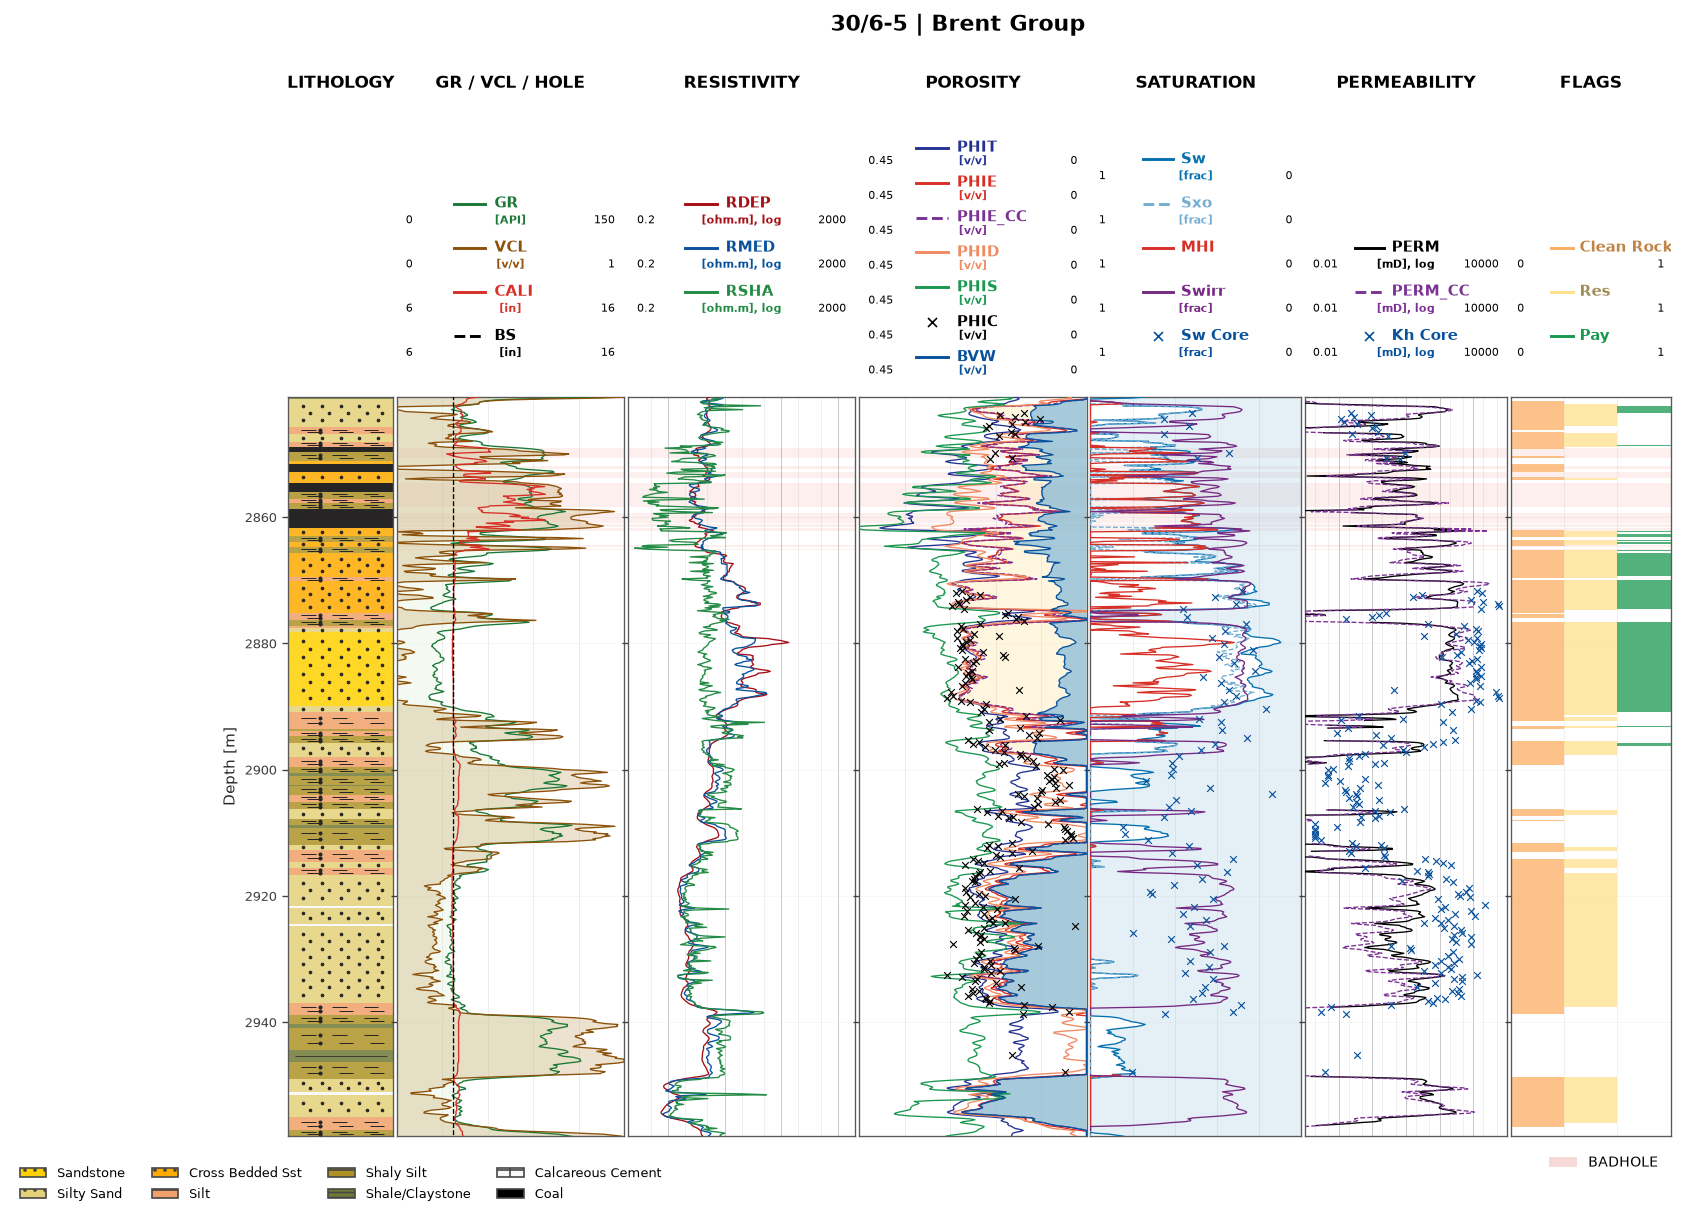

In [11]:
pp.plot(
    result,
    top=2841,
    bottom=2958,
    template="petrophysics",
    tracks=["LITHOLOGY", "GR / VCL / HOLE", "RESISTIVITY", "POROSITY",
            "SATURATION", "PERMEABILITY", "FLAGS"],
    formation_name="Brent Group",
    figsize=(12, 10),
).show()

## Export

`to_las` writes every curve plus the settings used (`PP_*` parameters).
`to_json` writes the complete trace.

In [12]:
import tempfile
from pathlib import Path

with tempfile.TemporaryDirectory() as folder:
    las_path = result.to_las(Path(folder) / "30_6-5_interpreted.las")
    json_path = result.to_json(Path(folder) / "30_6-5_trace.json")
    for path in (las_path, json_path):
        print(f"{path.name}: {path.stat().st_size / 1e3:,.0f} kB")
    for line in las_path.read_text().splitlines():
        if line.startswith("PP_"):          # the settings used, in the ~Params section
            name, *_, value = line.split(":")[0].split()
            if value.replace(".", "", 1).isdigit():
                value = f"{float(value):.3g}"
            print(f"  {name:<11} {value}")

30_6-5_interpreted.las: 14,201 kB
30_6-5_trace.json: 42 kB
  PP_VERSION  3.0.0
  PP_STATUS   interpreted
  PP_DOMAIN   clastic
  PP_MATRIX   sandstone
  PP_LITH     clastic
  PP_RW       0.07
  PP_RWTMIN   0.0624
  PP_RWTMAX   0.197
  PP_SWMODEL  archie+indonesia
  PP_A        lithology
  PP_M        2
  PP_N        2


## Several wells

`pp.read` and `pp.interpret` take a folder, a file pattern (`"logs/*.las"`) or a list of files as well as one file.
A multi-well tops table is read once and each well keeps its own picks; every well is interpreted with the same settings, its own header values filling the rest.
One table covers all the wells, and `to_las(folder)` and `save_plots(folder)` write a file per well.
A well that fails is named in `results.failed`; the others are interpreted.

In [13]:
wells = pp.read([pp.sample(name) for name in ["HW-3", "HW-4", "HW-5"]],
                formations=pp.sample("formations_costa"))
results = pp.interpret(wells, lithology_domain="carbonate")
results.summary().style.hide(axis="index").format(precision=3)

Well,Status,Depth unit,Net rock,Net reservoir,Net pay,Median VCL,Median PHIE,Median SW,Median PERM,Warnings
HW-3,interpreted,ft,215.500,195.000,194.000,0.000,0.216,0.102,1669.801,2
HW-4,interpreted,ft,180.500,142.500,4.000,0.000,0.181,1.000,172.815,3
HW-5,interpreted,ft,168.500,112.000,0.000,0.000,0.073,1.000,4.574,3


In [14]:
results.formation_summary().iloc[:, :8].style.hide(axis="index").format(precision=2)

    covers the other 308.
    covers the other 339.


Well,Formation,Top,Bottom,Gross (ft),Net Rock (ft),Net Reservoir (ft),Net Pay (ft)
HW-3,KHARAIB-2,7805.00,8020.00,215.50,215.50,195.00,194.00
HW-4,KHARAIB-2,8150.00,8330.00,180.50,180.50,142.50,4.00
HW-5,KHARAIB-2,8182.00,8350.00,168.50,168.50,112.00,0.00


`pp.plot` on several wells draws each well's own log plot, one after another; `.save(folder)` writes a file per well.
With `curves=`, it draws one figure instead: a track per curve, with every well's curve in it.

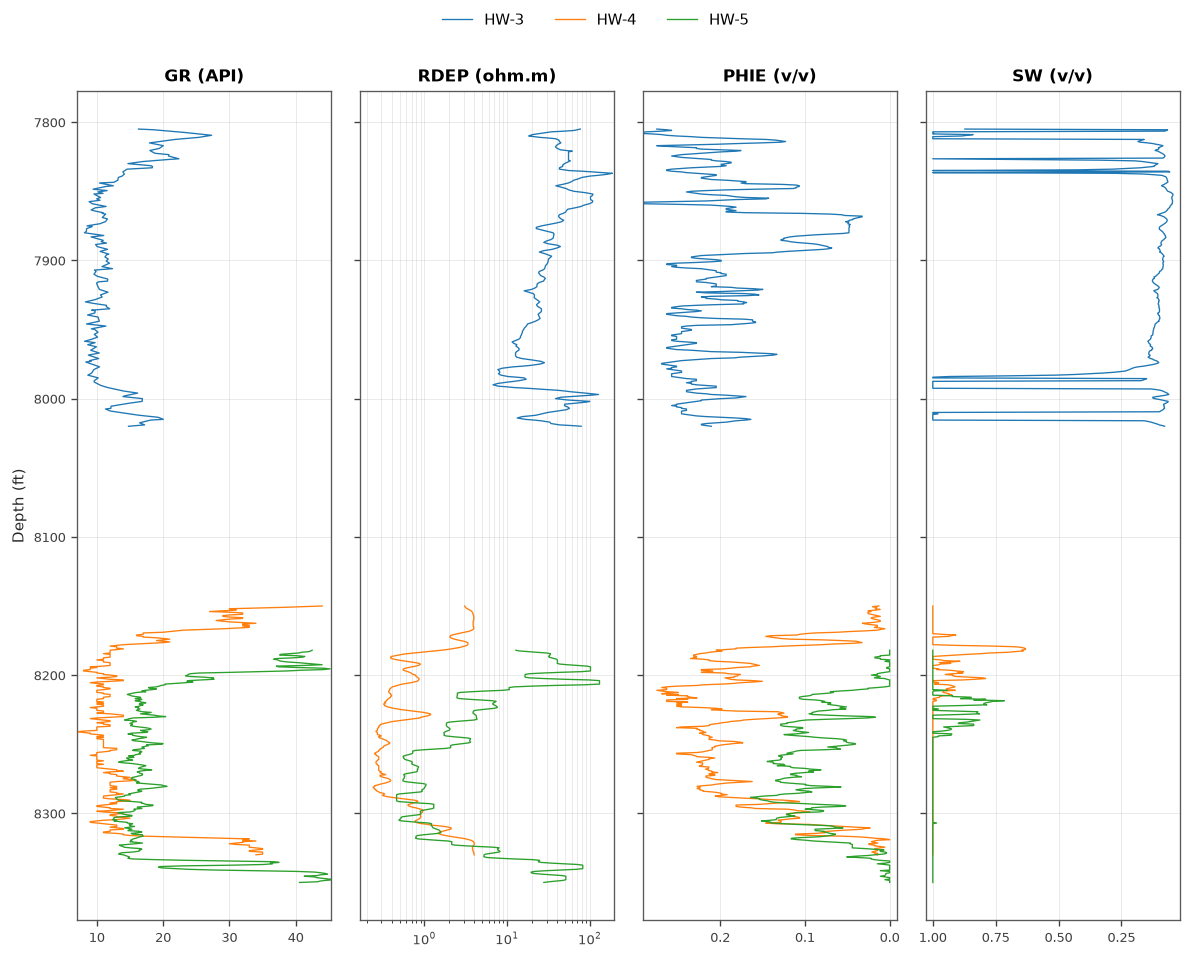

In [15]:
pp.plot(results, curves=["GR", "RDEP", "PHIE", "SW"], figsize=(10, 8)).show()

## Next

[Your own data](https://petrophys.netlify.app/own_data.html): read your own CSV logs, attach formation and lithology tables, and check that their depths agree.

The [complete tour](https://petrophys.netlify.app/tutorials/complete_tour.html) runs every capability of the library on bundled data in one notebook, and the [30/6-5 case study](https://petrophys.netlify.app/tutorials/case_studies/cs1_full_formation_evaluation_30_6-5.html) evaluates this well step by step.